<a href="https://colab.research.google.com/github/natenorris10/STP494_Applied_Machine_Learning/blob/main/ML_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.3 MB/s eta 0:00:00


In [ ]:
# The basic libraries
import pandas as pd
import numpy as np

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling
import xgboost as xgb
from catboost import CatBoostClassifier
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import learning_curve, validation_curve

from sklearn.preprocessing import StandardScaler


# Model Performance and Feature Importance
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
import shap

In [ ]:
dementia_df = pd.read_csv('/content/alzheimers_disease_data.csv')

#EDA

In [ ]:
dementia_df.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


In [ ]:
# some basic info
display(dementia_df.shape)
dementia_df.info()

(2149, 35)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

In [ ]:
# DoctorInCharge, PatientID is not needed
dementia_df.drop(columns=['DoctorInCharge', 'PatientID'], inplace=True)

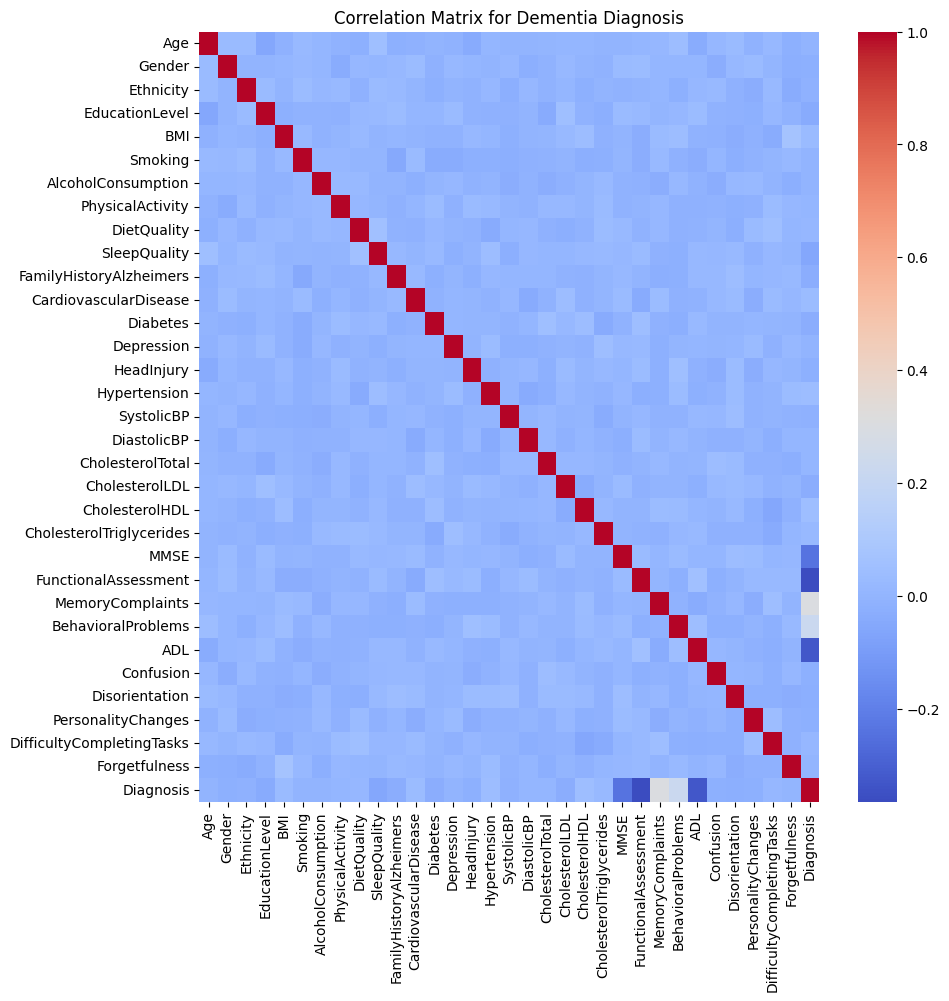

In [ ]:
# Correlation Matrix
plt.figure(figsize=(10,10))
sns.heatmap(dementia_df.corr(), annot=False, cmap='coolwarm')
plt.title('Correlation Matrix for Dementia Diagnosis')
plt.show()

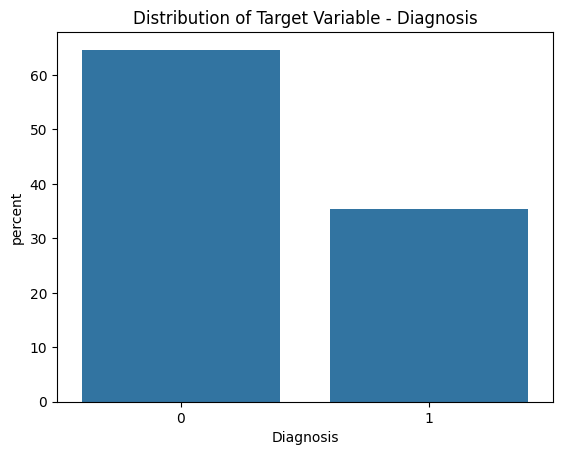

,count
Diagnosis,
0,1389
1,760


In [ ]:
# Distribution of target
sns.countplot(data=dementia_df, x=dementia_df['Diagnosis'], stat='percent')
plt.title('Distribution of Target Variable - Diagnosis')
plt.show()
display(dementia_df['Diagnosis'].value_counts())

In [ ]:
# Histogram function
def histogram(list):
  fig, ax = plt.subplots(3, 5, figsize=(28,12))

  for i in range(0, len(list)):
    sns.histplot(data=dementia_df, x=dementia_df[list[i]], bins=20, ax=ax[int(i/5), i % 5])
  plt.show()


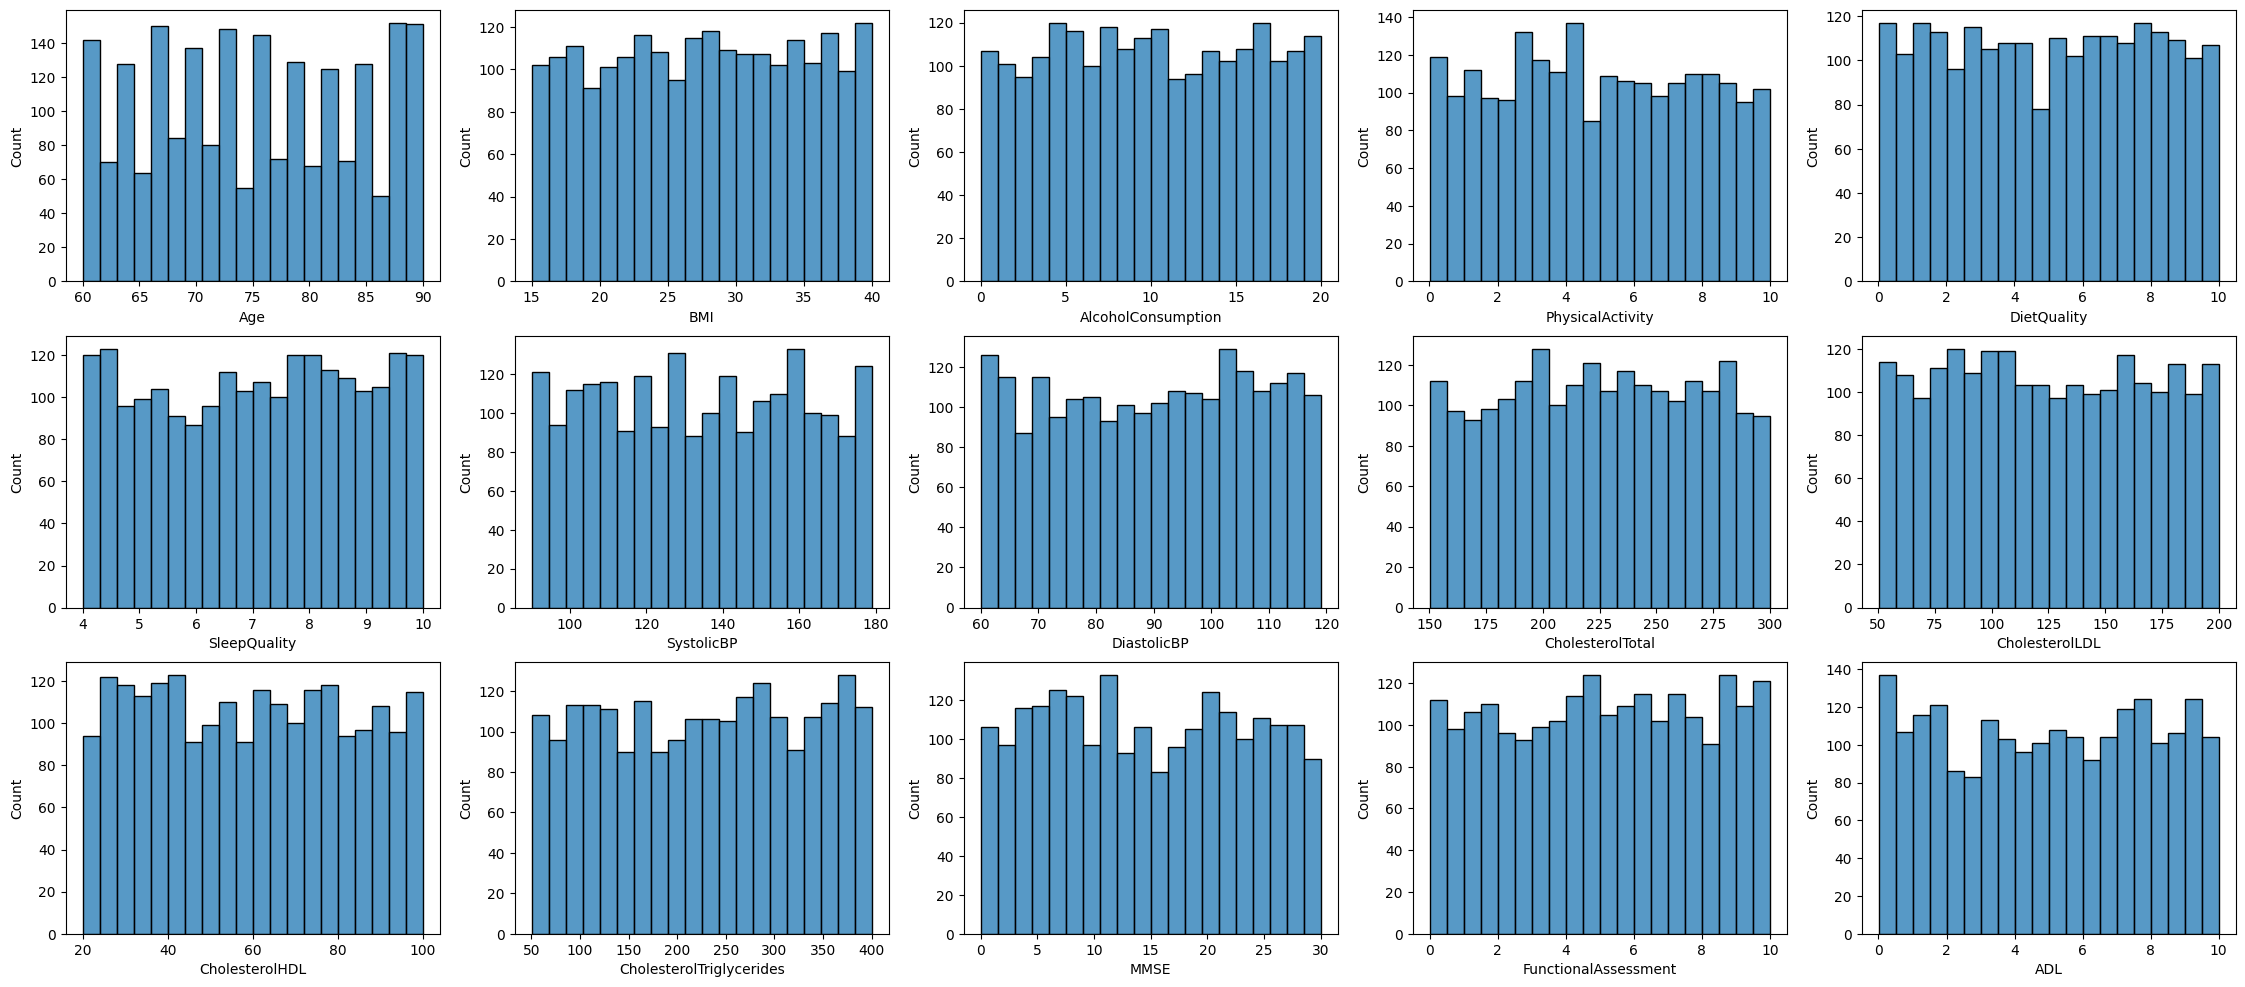

In [ ]:
# Distribution of numerical features
numerical_features = ['Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality',
                      'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
                      'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'ADL']

histogram(numerical_features)

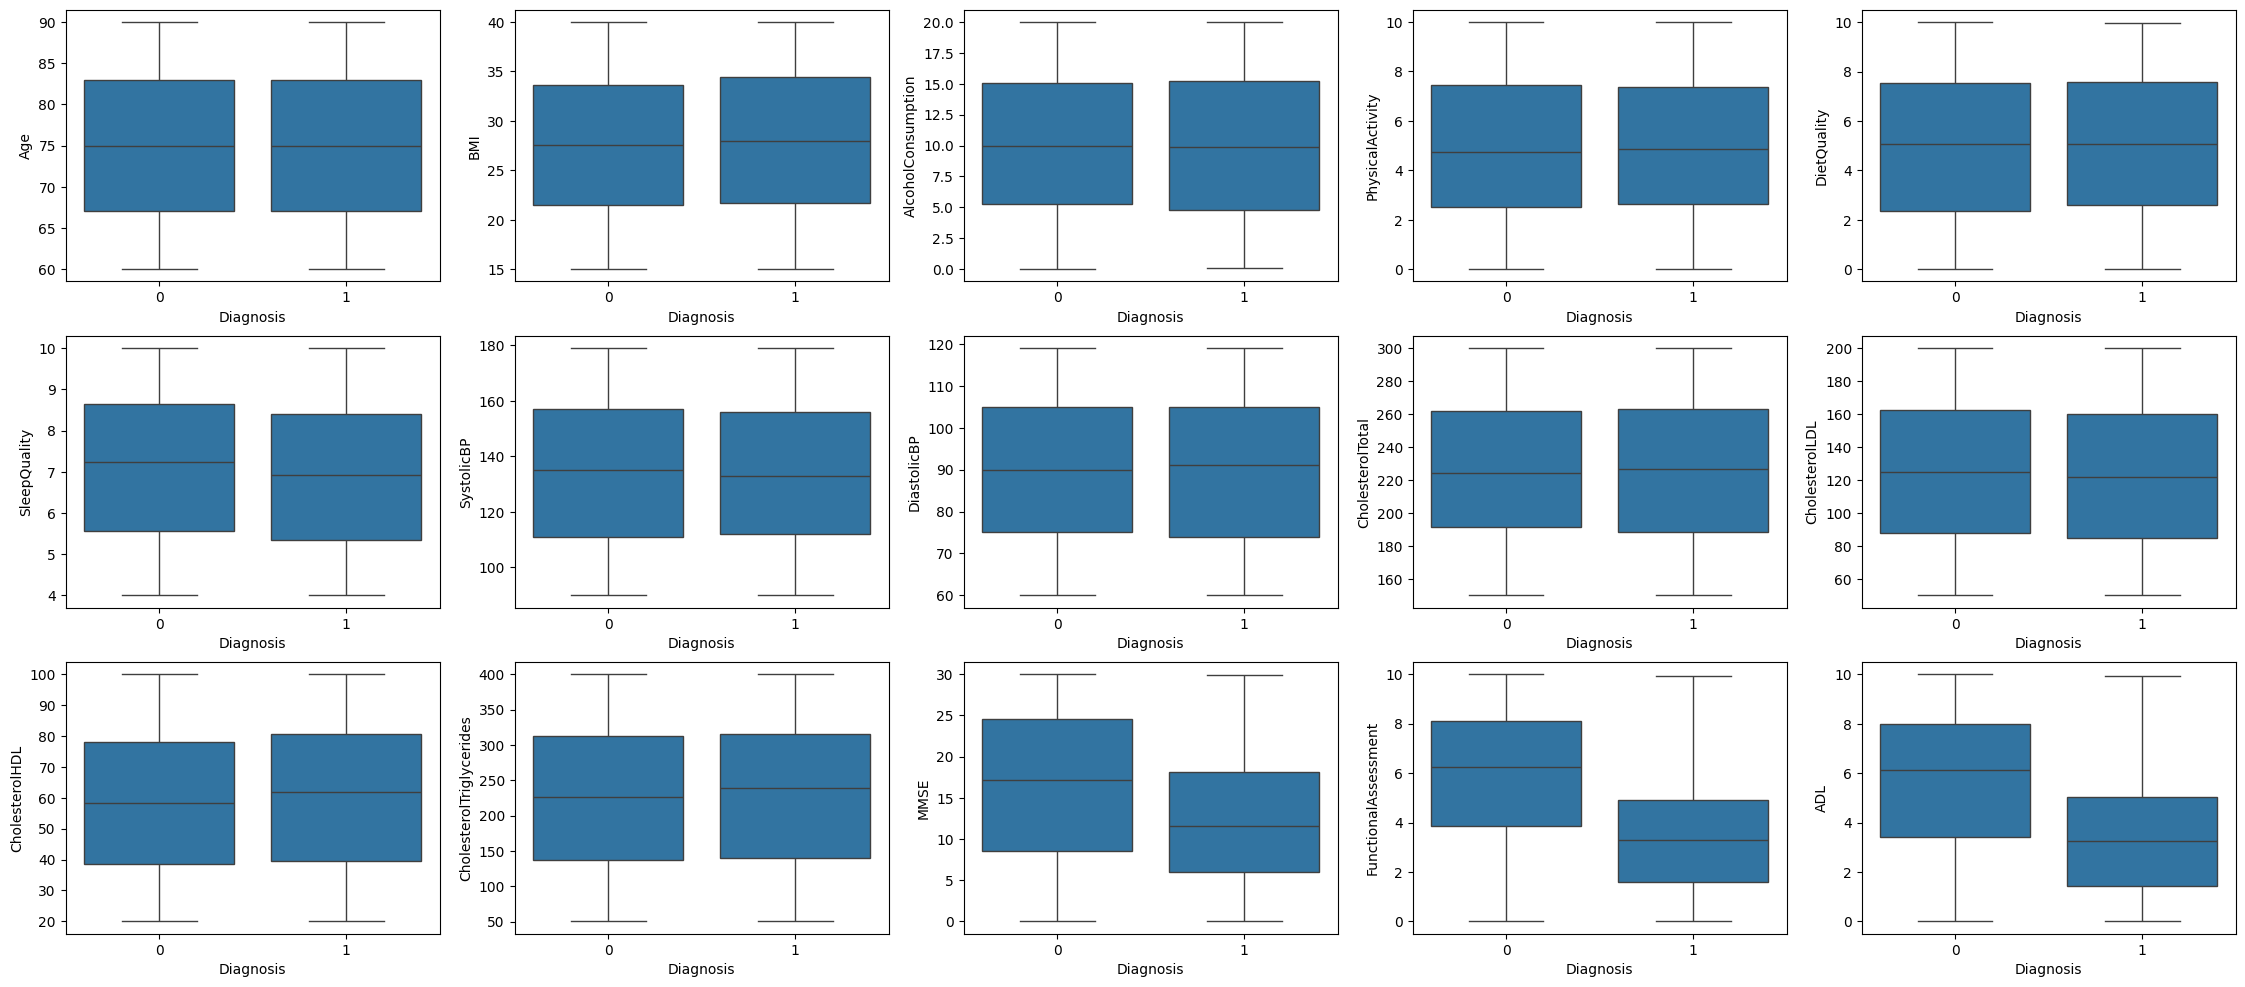

In [ ]:
# Box plot of numerical features
fig, ax = plt.subplots(3, 5, figsize=(28,12))

for i in range(0, len(numerical_features)):
  sns.boxplot(data=dementia_df, x=dementia_df['Diagnosis'], y=dementia_df[numerical_features[i]], ax=ax[int(i/5), i % 5])
plt.show()

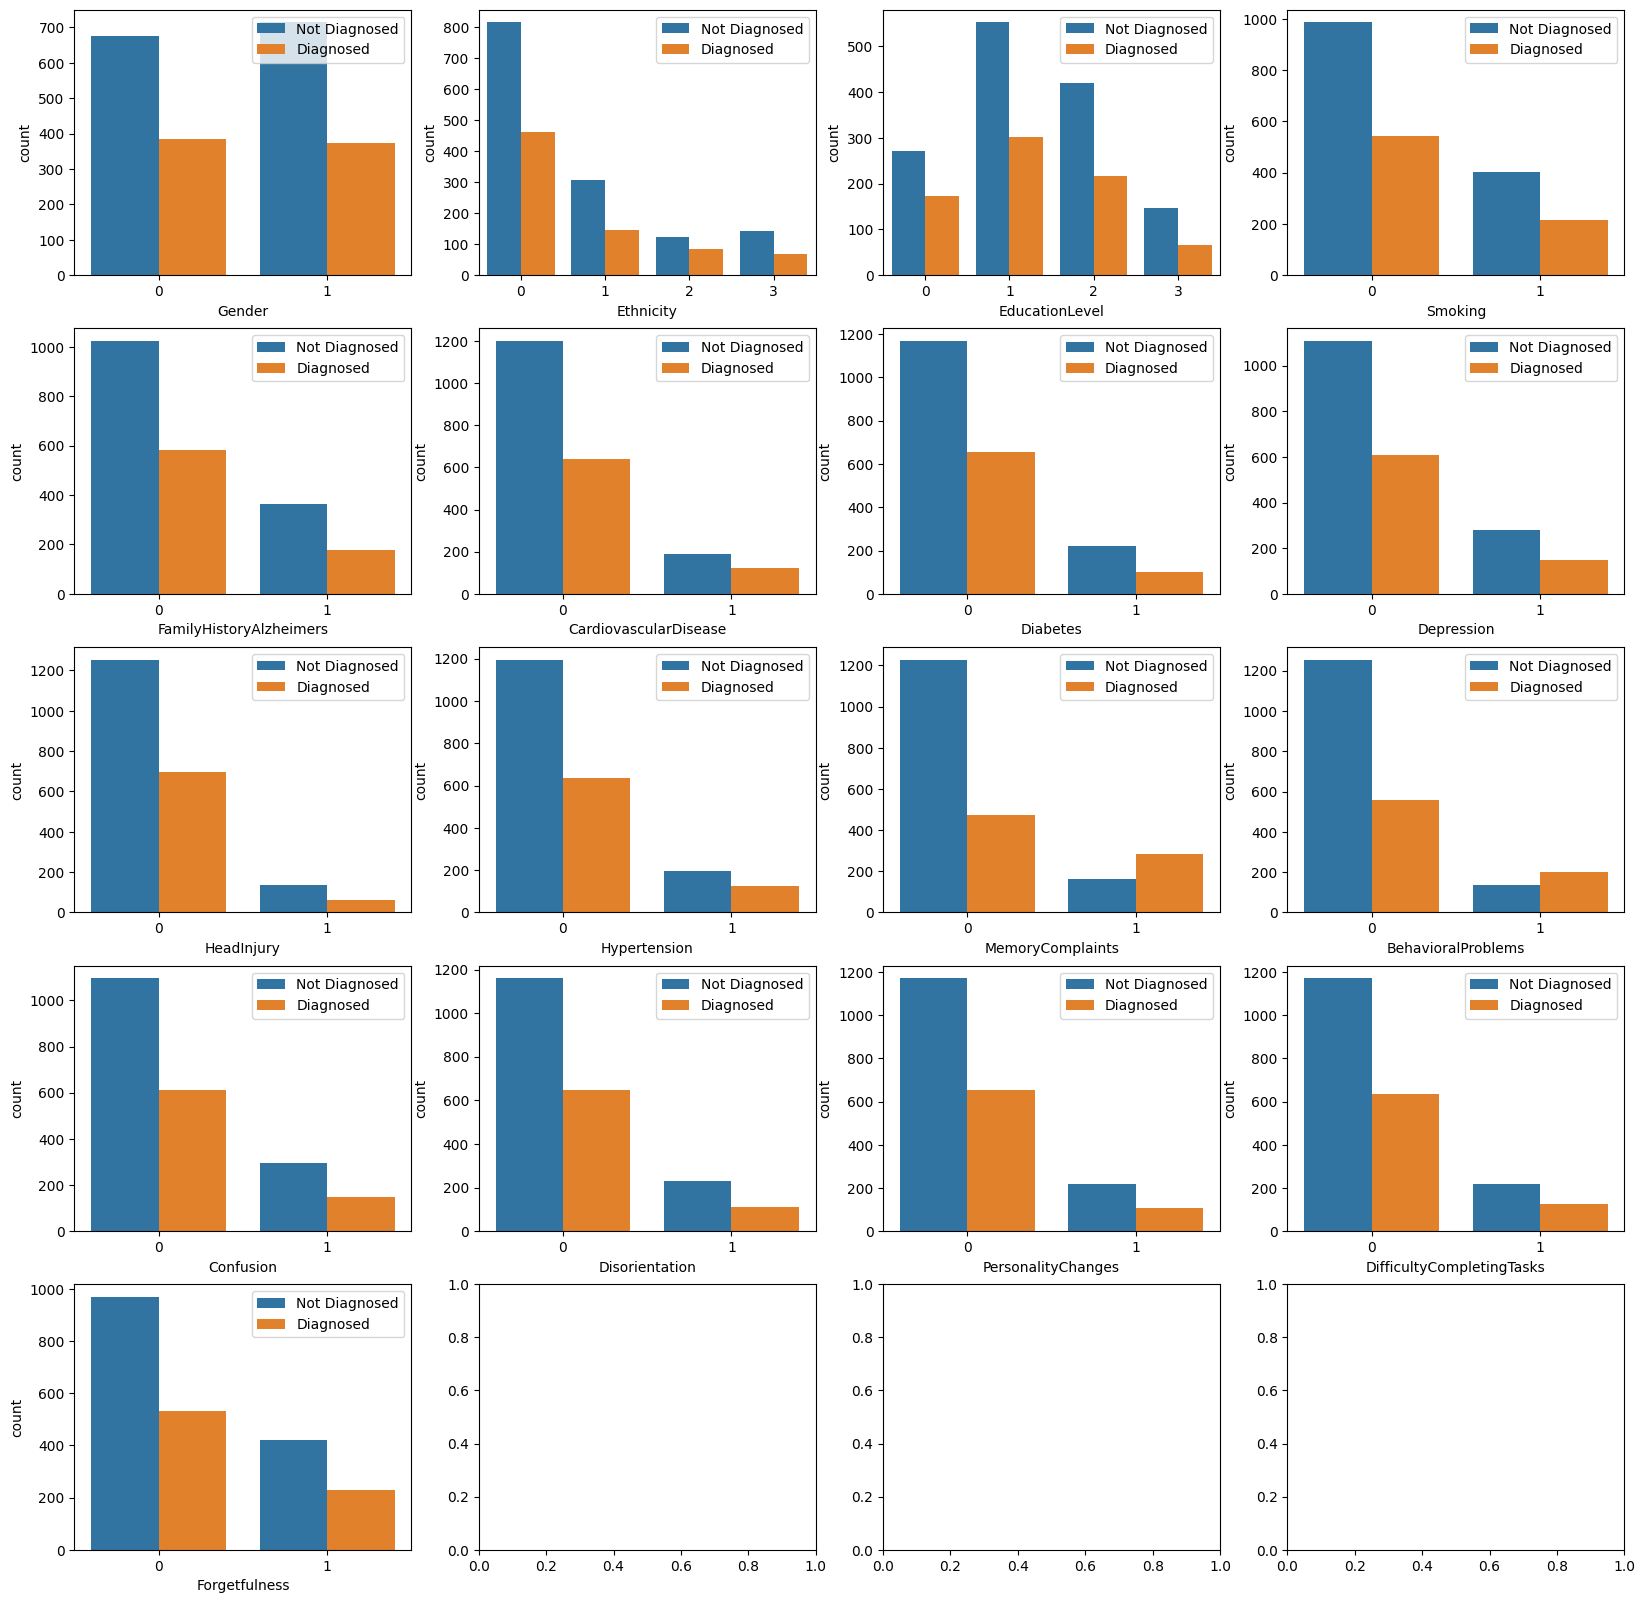

In [ ]:
# Plot for categorical features
categorical_features = ['Gender', 'Ethnicity', 'EducationLevel', 'Smoking', 'FamilyHistoryAlzheimers',
                        'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension',
                        'MemoryComplaints', 'BehavioralProblems', 'Confusion', 'Disorientation',
                        'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness']

fig, ax = plt.subplots(5, 4, figsize=(20,20))

for feature, ax in zip(categorical_features, ax.flatten()):
  cplot = sns.countplot(data=dementia_df, x=dementia_df[feature], hue=dementia_df['Diagnosis'], ax=ax)
  cplot.legend(['Not Diagnosed', 'Diagnosed'])
plt.show()

#Building XGBoost Model

In [ ]:
# Separating ethnicity into different categories
dementia_df = pd.get_dummies(dementia_df, columns=['Ethnicity'], prefix='Ethnicity', drop_first=False)
dementia_df.head()

,Age,Gender,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryAlzheimers,...,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,Ethnicity_0,Ethnicity_1,Ethnicity_2,Ethnicity_3
0,73,0,2,22.927749,0,13.297218,6.327112,1.347214,9.025679,0,...,0,0,0,1,0,0,True,False,False,False
1,89,0,0,26.827681,0,4.542524,7.619885,0.518767,7.151293,0,...,0,0,0,0,1,0,True,False,False,False
2,73,0,1,17.795882,0,19.555085,7.844988,1.826335,9.673574,1,...,0,1,0,1,0,0,False,False,False,True
3,74,1,1,33.800817,1,12.209266,8.428001,7.435604,8.392554,0,...,0,0,0,0,0,0,True,False,False,False
4,89,0,0,20.716974,0,18.454356,6.310461,0.795498,5.597238,0,...,0,0,1,1,0,0,True,False,False,False


In [ ]:
# Separate X and target y
X = dementia_df.drop(columns=['Diagnosis'])
y = dementia_df['Diagnosis']

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Baseline Model with no specification
xgb_baseline = xgb.XGBClassifier(eval_metric='logloss')
xgb_baseline.fit(X_train, y_train)
xgb_baseline.score(X_test, y_test)

0.9558139534883721

In [ ]:
# Classification Report
print(classification_report(y_test, xgb_baseline.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430



In [ ]:
# Cross val score with baseline
xgb_baseline_cv = cross_val_score(xgb_baseline, X, y, cv=10, scoring='accuracy')
print(f'CV Mean: {xgb_baseline_cv.mean():.3f} (+/- {xgb_baseline_cv.std():.3f})')

CV Mean: 0.950 (+/- 0.091)


In [ ]:
# Checking difference between test/train accuracy
xgb_baseline_train_acc = xgb_baseline.score(X_train, y_train)
xgb_baseline_test_acc = xgb_baseline.score(X_test, y_test)

# Gap
print(f"Train/Test Gap: {abs(xgb_baseline_train_acc - xgb_baseline_test_acc):.2f}")

Train/Test Gap: 0.04


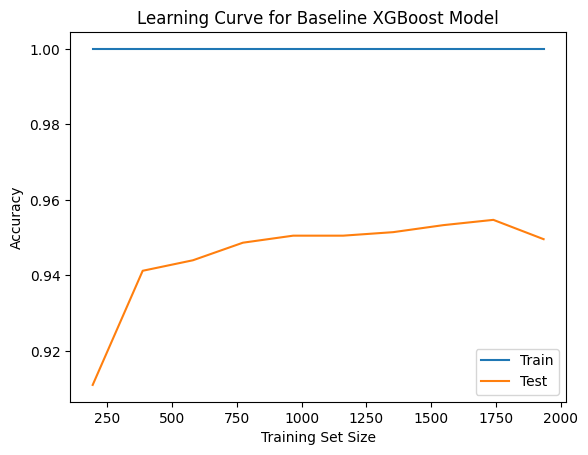

In [ ]:
# Plotting learning curve
xgb_baseline_train_sizes, xgb_baseline_train_scores, xgb_baseline_test_scores = learning_curve(
    xgb_baseline, X, y, cv=10, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
    )

plt.plot(xgb_baseline_train_sizes, xgb_baseline_train_scores.mean(axis=1), label='Train')
plt.plot(xgb_baseline_train_sizes, xgb_baseline_test_scores.mean(axis=1), label='Test')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve for Baseline XGBoost Model')
plt.legend()
plt.show()

##RandomizedSearchCV

In [ ]:
# Scaling pos_weight
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
pos_weight = round(neg/pos, 2)
print(pos_weight)

1.83


In [ ]:
# Starting RandomizedCV
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.1, 0.5, 1.0],
    'reg_lambda': [0.5, 1.0, 2.0, 5.0]
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

xgb_random_search = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(eval_metric='logloss', scale_pos_weight=pos_weight),
    param_distributions=param_dist,
    n_iter=50,
    scoring='accuracy',
    cv=skf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random_search.fit(X_train, y_train)

print(f"Best Parameters: {xgb_random_search.best_params_}")
print(f"Best Score: {xgb_random_search.best_score_:.3f}")

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Parameters: {'subsample': 0.6, 'reg_lambda': 0.5, 'reg_alpha': 1.0, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Best Score: 0.951


In [ ]:
# Checking that models classification report
xgb_random_best_model = xgb_random_search.best_estimator_
print(classification_report(y_test, xgb_random_best_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430



In [ ]:
# Cross val score with best randomcv model
xgb_random_best_model_cv = cross_val_score(xgb_random_best_model, X, y, cv=10, scoring='accuracy')
print(f'CV Mean: {xgb_random_best_model_cv.mean():.3f} (+/- {xgb_random_best_model_cv.std():.3f})')

CV Mean: 0.953 (+/- 0.093)


In [ ]:
# Checking gap
rand_best_train_acc = xgb_random_best_model.score(X_train, y_train)
rand_best_test_acc = xgb_random_best_model.score(X_test, y_test)
print(f"Train/Test Gap: {rand_best_train_acc - rand_best_test_acc:.4f}")

Train/Test Gap: 0.0011


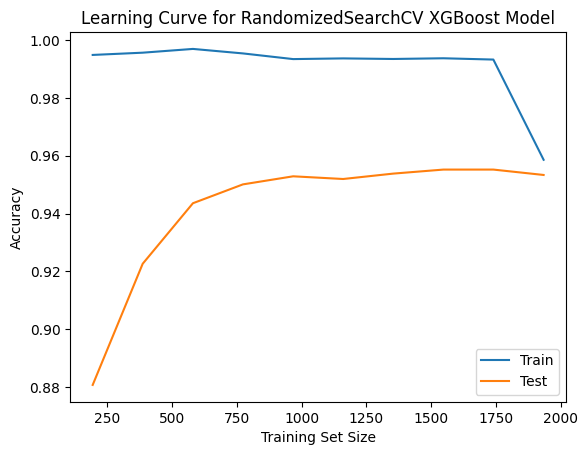

In [ ]:
# Plotting learning curve

xgb_rand_best_train_sizes, xgb_rand_best_train_scores, xgb_rand_best_test_scores = learning_curve(
    xgb_random_best_model, X, y, cv=10, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
    )

plt.plot(xgb_rand_best_train_sizes, xgb_rand_best_train_scores.mean(axis=1), label='Train')
plt.plot(xgb_rand_best_train_sizes, xgb_rand_best_test_scores.mean(axis=1), label='Test')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve for RandomizedSearchCV XGBoost Model')
plt.legend()
plt.show()

##GridSearchCV

In [ ]:
# GridSearchCV Around RandomSearhCV results
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.005, 0.01, 0.05],
    'n_estimators': [200, 300, 400],
    'reg_alpha': [0.5, 1.0, 2.0]
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

xgb_grid_search = GridSearchCV(
    estimator=xgb.XGBClassifier(eval_metric='logloss', scale_pos_weight=pos_weight),
    param_grid=param_grid,
    scoring='accuracy',
    cv=skf,
    n_jobs=-1,
    verbose=1
)

xgb_grid_search.fit(X_train, y_train)

print(f"Best Params: {xgb_grid_search.best_params_}")
print(f"Best Accuracy Score: {xgb_grid_search.best_score_:.3f}")

Fitting 10 folds for each of 81 candidates, totalling 810 fits
Best Params: {'learning_rate': 0.005, 'max_depth': 5, 'n_estimators': 300, 'reg_alpha': 0.5}
Best Accuracy Score: 0.951


In [ ]:
# Classisfication report for grid search
xgb_grid_best_model = xgb_grid_search.best_estimator_
print(classification_report(y_test, xgb_grid_best_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.96      0.97      0.96       277
           1       0.94      0.92      0.93       153

    accuracy                           0.95       430
   macro avg       0.95      0.94      0.95       430
weighted avg       0.95      0.95      0.95       430



In [ ]:
# Cross val score with grid search model
xgb_grid_best_model_cv = cross_val_score(xgb_grid_best_model, X, y, cv=10, scoring='accuracy')
print(f'CV Mean: {xgb_grid_best_model_cv.mean():.3f} (+/- {xgb_grid_best_model_cv.std():.3f})')

CV Mean: 0.950 (+/- 0.092)


In [ ]:
# Gap in train/test for grid search
grid_best_train_acc = xgb_grid_best_model.score(X_train, y_train)
grid_best_test_acc = xgb_grid_best_model.score(X_test, y_test)
print(f"Train/Test Gap: {grid_best_train_acc - grid_best_test_acc:.4f}")

Train/Test Gap: 0.0099


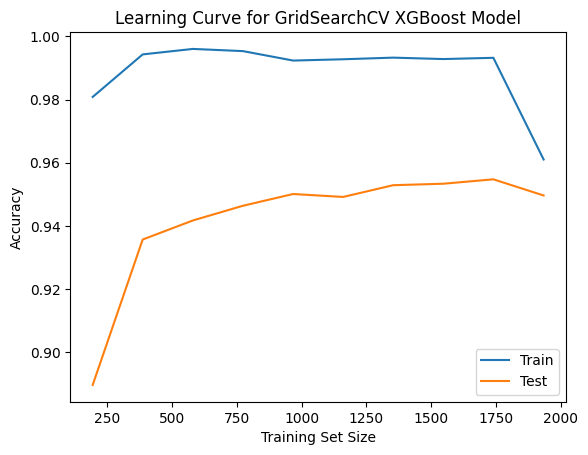

In [ ]:
# Plotting learning curve

xgb_grid_best_train_sizes, xgb_grid_best_train_scores, xgb_grid_best_test_scores = learning_curve(
    xgb_grid_best_model, X, y, cv=10, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
    )

plt.plot(xgb_grid_best_train_sizes, xgb_grid_best_train_scores.mean(axis=1), label='Train')
plt.plot(xgb_grid_best_train_sizes, xgb_grid_best_test_scores.mean(axis=1), label='Test')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve for GridSearchCV XGBoost Model')
plt.legend()
plt.show()

###Validation Curves for Max Depth

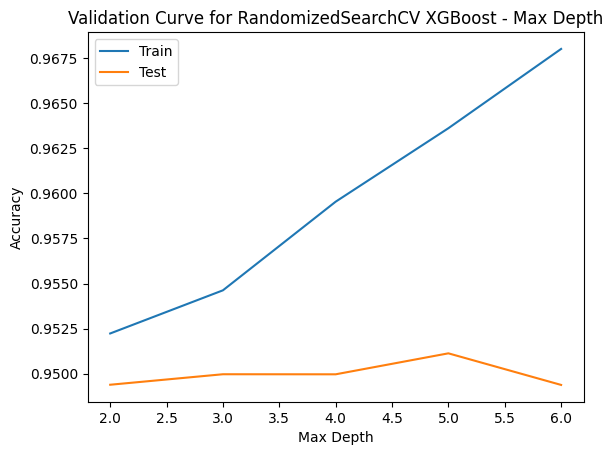

In [ ]:
# Validation curve for RandomizedSearch
# 'subsample': 0.6, 'reg_lambda': 0.5, 'reg_alpha': 1.0, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.6

xgb_rand_train_scores, xgb_rand_test_scores = validation_curve(
    xgb.XGBClassifier(
        eval_metric='logloss',
        scale_pos_weight=pos_weight,
        subsample=0.6,
        reg_lambda=0.5,
        reg_alpha=1.0,
        n_estimators=300,
        learning_rate=0.01,
        colsample_bytree=0.6,
    ),
    X_train, y_train,
    param_name='max_depth',
    param_range=[2, 3, 4, 5, 6],
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

plt.plot([2,3,4,5,6], xgb_rand_train_scores.mean(axis=1), label='Train')
plt.plot([2,3,4,5,6], xgb_rand_test_scores.mean(axis=1), label='Test')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Validation Curve for RandomizedSearchCV XGBoost - Max Depth')
plt.legend()
plt.show()

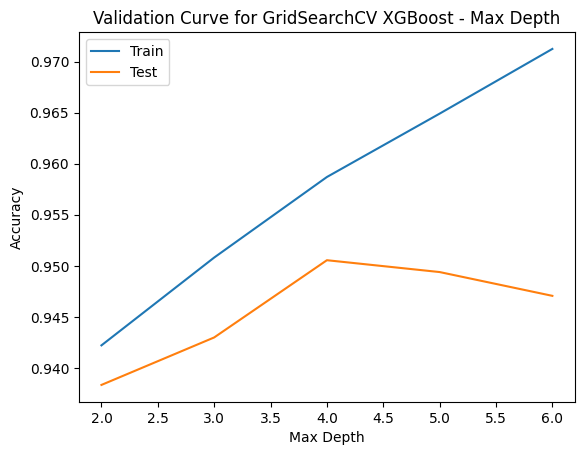

In [ ]:
# Validation Curve for GridSearch

xgb_grid_train_scores, xgb_grid_test_scores = validation_curve(
    xgb.XGBClassifier(
        learning_rate=0.01,
        n_estimators=400,
        reg_alpha=1.0,
        eval_metric='logloss'
    ),
    X_train, y_train,
    param_name='max_depth',
    param_range=[2, 3, 4, 5, 6],
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

plt.plot([2,3,4,5,6], xgb_grid_train_scores.mean(axis=1), label='Train')
plt.plot([2,3,4,5,6], xgb_grid_test_scores.mean(axis=1), label='Test')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Validation Curve for GridSearchCV XGBoost - Max Depth')
plt.legend()
plt.show()

##Building XGBoost with Max Depth 2

In [ ]:
#RandomizedSearch with max depth 2

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [2],
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.1, 0.5, 1.0],
    'reg_lambda': [0.5, 1.0, 2.0, 5.0]
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

xgb_rand_maxdepth2 = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(eval_metric='logloss', scale_pos_weight=pos_weight),
    param_distributions=param_dist,
    n_iter=50,
    scoring='accuracy',
    cv=skf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_rand_maxdepth2.fit(X_train, y_train)

print(f"Best Parameters: {xgb_rand_maxdepth2.best_params_}")
print(f"Best Score: {xgb_rand_maxdepth2.best_score_:.3f}")

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Parameters: {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
Best Score: 0.951


In [ ]:
# Classification Report
xgb_rand_maxdepth2_best_model = xgb_rand_maxdepth2.best_estimator_
print(classification_report(y_test, xgb_rand_maxdepth2_best_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.96      0.97      0.96       277
           1       0.95      0.92      0.93       153

    accuracy                           0.95       430
   macro avg       0.95      0.95      0.95       430
weighted avg       0.95      0.95      0.95       430



In [ ]:
# Cross Validation
xgb_rand_maxdepth2_cv = cross_val_score(xgb_rand_maxdepth2_best_model, X, y, cv=10, scoring='accuracy')
print(f'CV Mean: {xgb_rand_maxdepth2_cv.mean():.3f} (+/- {xgb_rand_maxdepth2_cv.std():.3f})')

CV Mean: 0.950 (+/- 0.092)


In [ ]:
# Train/Test Gap
xgb_rand_maxdepth2_train_acc = xgb_rand_maxdepth2_best_model.score(X_train, y_train)
xgb_rand_maxdepth2_test_acc = xgb_rand_maxdepth2_best_model.score(X_test, y_test)
print(f"Train/Test Gap: {xgb_rand_maxdepth2_train_acc - xgb_rand_maxdepth2_test_acc:.4f}")

Train/Test Gap: 0.0006


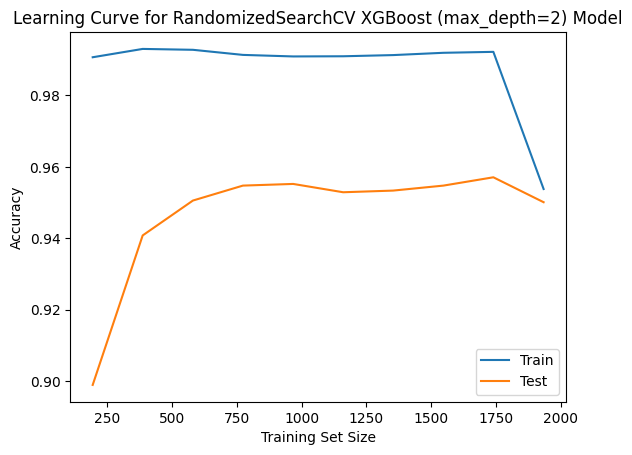

In [ ]:
# Learning Curve

xgb_rand_maxdepth2_train_sizes, xgb_rand_maxdepth2_train_scores, xgb_rand_maxdepth2_test_scores = learning_curve(
    xgb_rand_maxdepth2_best_model, X, y, cv=10, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.plot(xgb_rand_maxdepth2_train_sizes, xgb_rand_maxdepth2_train_scores.mean(axis=1), label='Train')
plt.plot(xgb_rand_maxdepth2_train_sizes, xgb_rand_maxdepth2_test_scores.mean(axis=1), label='Test')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve for RandomizedSearchCV XGBoost (max_depth=2) Model')
plt.legend()
plt.show()

#Building CatBoost Model

In [ ]:
# Messing around with CatBoost
cat_baseline = CatBoostClassifier(random_state=42, verbose=0)
cat_baseline.fit(X_train, y_train)
cat_baseline.score(X_test, y_test)

np.float64(0.9558139534883721)

In [ ]:
# Classification Report
print(classification_report(y_test, cat_baseline.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430



In [ ]:
# cross validation
cat_baseline_cv = cross_val_score(cat_baseline, X, y, cv=10, scoring='accuracy')
print(f'CV Mean: {cat_baseline_cv.mean():.3f} (+/-) {cat_baseline_cv.std():.3f}')

CV Mean: 0.955 (+/- 0.093


In [ ]:
# Train/Test Gap
cat_baseline_train_acc = cat_baseline.score(X_train, y_train)
cat_baseline_test_acc = cat_baseline.score(X_test, y_test)
print(f'Train/Test Gap: {(cat_baseline_train_acc - cat_baseline_test_acc):.2f}')

Train/Test Gap: 0.03


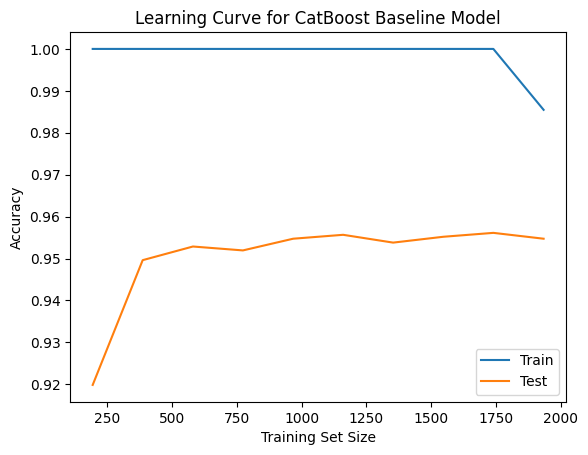

In [ ]:
# Learning Curve

cat_baseline_train_sizes, cat_baseline_train_scores, cat_baseline_test_scores = learning_curve(
    cat_baseline, X, y, cv=10, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.plot(cat_baseline_train_sizes, cat_baseline_train_scores.mean(axis=1), label='Train')
plt.plot(cat_baseline_train_sizes, cat_baseline_test_scores.mean(axis=1), label='Test')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve for CatBoost Baseline Model')
plt.legend()
plt.show()

##RandomizedSearchCV CatBoost

In [ ]:
# list of categorical features (ethnicity no longer categorical)
cat_features = ['Gender', 'EducationLevel', 'Smoking', 'FamilyHistoryAlzheimers',
                        'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension',
                        'MemoryComplaints', 'BehavioralProblems', 'Confusion', 'Disorientation',
                        'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness']

In [ ]:
# Building Randomized Search

param_dist = {
    'iterations': [100, 200, 300, 500],
    'max_depth': [2, 3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'l2_leaf_reg': [1, 3, 5, 7, 10],  # CatBoost's equivalent of reg_lambda
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bylevel': [0.6, 0.7, 0.8, 0.9, 1.0]  # CatBoost's equivalent of colsample_bytree
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

random_search_cat = RandomizedSearchCV(
    estimator=CatBoostClassifier(
        random_state=42, verbose=0, thread_count=1, eval_metric='Accuracy'
        ),
    param_distributions=param_dist,
    n_iter=50,
    scoring='accuracy',
    cv=skf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_cat.fit(X_train, y_train, cat_features=cat_features)

print(f"Best Params: {random_search_cat.best_params_}")
print(f"Best Accuracy Score: {random_search_cat.best_score_:.4f}")

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Params: {'subsample': 1.0, 'max_depth': 6, 'learning_rate': 0.2, 'l2_leaf_reg': 7, 'iterations': 500, 'colsample_bylevel': 0.6}
Best Accuracy Score: 0.9558


In [ ]:
# Classification Report
cat_rand_best_model = random_search_cat.best_estimator_
print(classification_report(y_test, cat_rand_best_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430



In [ ]:
# Cross validation
cat_rand_best_model_cv = cross_val_score(cat_rand_best_model, X, y, cv=10, scoring='accuracy')
print(f'CV Mean: {cat_rand_best_model_cv.mean():.3f} (+/- {cat_rand_best_model_cv.std():.3f})')

CV Mean: 0.954 (+/- 0.093)


In [ ]:
# Train/Test Gap
cat_rand_best_train_acc = cat_rand_best_model.score(X_train, y_train)
cat_rand_best_test_acc = cat_rand_best_model.score(X_test, y_test)
print(f"Train/Test Gap: {cat_rand_best_train_acc - cat_rand_best_test_acc:.4f}")

Train/Test Gap: 0.0442


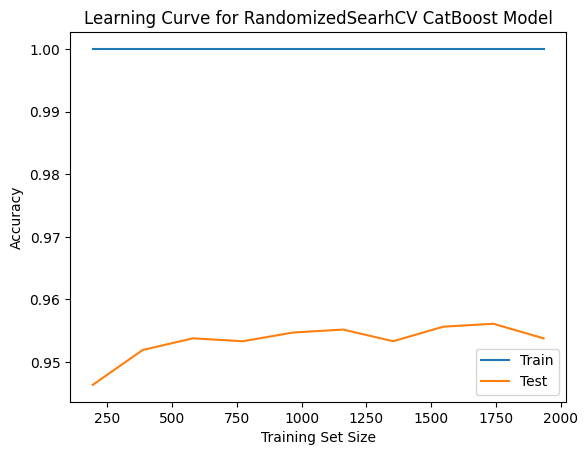

In [ ]:
# Learning Curve

cat_rand_best_train_sizes, cat_rand_best_train_scores, cat_rand_best_test_scores = learning_curve(
    cat_rand_best_model, X, y, cv=10, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.plot(cat_rand_best_train_sizes, cat_rand_best_train_scores.mean(axis=1), label='Train')
plt.plot(cat_rand_best_train_sizes, cat_rand_best_test_scores.mean(axis=1), label='Test')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve for RandomizedSearhCV CatBoost Model')
plt.legend()
plt.show()

##RandomizedSearch with max_depth validation curve

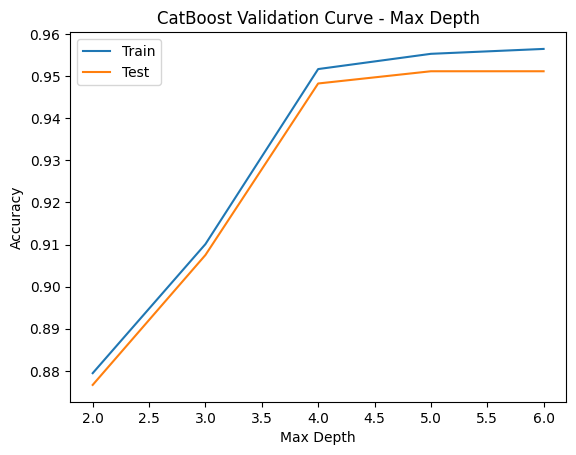

In [ ]:
# Validation Curve

cat_train_scores, cat_test_scores = validation_curve(
    CatBoostClassifier(
        iterations=100,
        learning_rate=0.01,
        l2_leaf_reg=7,
        colsample_bylevel=0.6,
        random_state=42,
        verbose=0,
        thread_count=1
    ),
    X_train, y_train,
    param_name='max_depth',
    param_range=[2, 3, 4, 5, 6],
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

plt.plot([2,3,4,5,6], cat_train_scores.mean(axis=1), label='Train')
plt.plot([2,3,4,5,6], cat_test_scores.mean(axis=1), label='Test')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('CatBoost Validation Curve - Max Depth')
plt.legend()
plt.show()

In [ ]:
# Randomized Search with max_depth [2, 3, 4]

param_dist = {
    'iterations': [50, 100, 150, 200],
    'max_depth': [2, 3, 4],          # cap at 4 based on validation curve
    'learning_rate': [0.01, 0.05, 0.1],
    'l2_leaf_reg': [5, 7, 10],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bylevel': [0.5, 0.6, 0.7]
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cat_maxdepth = RandomizedSearchCV(
    estimator=CatBoostClassifier(
        random_state=42, verbose=0, thread_count=1, eval_metric='Accuracy'
        ),
    param_distributions=param_dist,
    n_iter=50,
    scoring='accuracy',
    cv=skf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

cat_maxdepth.fit(X_train, y_train, cat_features=cat_features)

print(f"Best Params: {cat_maxdepth.best_params_}")
print(f"Best Accuracy Score: {cat_maxdepth.best_score_:.4f}")

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Params: {'subsample': 0.7, 'max_depth': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 7, 'iterations': 200, 'colsample_bylevel': 0.5}
Best Accuracy Score: 0.9541


In [ ]:
# Classification report
cat_maxdepth_best_model = cat_maxdepth.best_estimator_
print(classification_report(y_test, cat_maxdepth_best_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96       277
           1       0.96      0.91      0.93       153

    accuracy                           0.95       430
   macro avg       0.95      0.94      0.95       430
weighted avg       0.95      0.95      0.95       430



In [ ]:
# Cross Validation
cat_maxdepth_best_model_cv = cross_val_score(cat_maxdepth_best_model, X, y, cv=10, scoring='accuracy')
print(f'CV Mean: {cat_maxdepth_best_model_cv.mean():.3f} (+/-) {cat_maxdepth_best_model_cv.std():.3f})')

CV Mean: 0.953 (+/-) 0.093)


In [ ]:
# Train/Test gap
cat_maxdepth_best_train_acc = cat_maxdepth_best_model.score(X_train, y_train)
cat_maxdepth_best_test_acc = cat_maxdepth_best_model.score(X_test, y_test)
print(f"Train/Test Gap: {cat_maxdepth_best_train_acc - cat_maxdepth_best_test_acc:.4f}")

Train/Test Gap: 0.0011


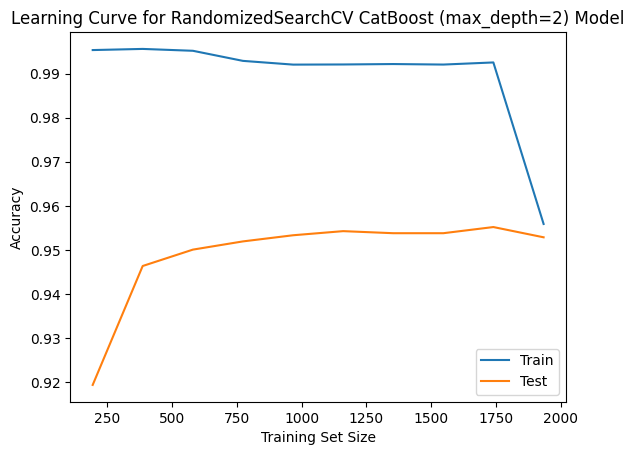

In [ ]:
# Learning Curve

cat_maxdepth_best_train_sizes, cat_maxdepth_best_train_scores, cat_maxdepth_best_test_scores = learning_curve(
    cat_maxdepth_best_model, X, y, cv=10, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.plot(cat_maxdepth_best_train_sizes, cat_maxdepth_best_train_scores.mean(axis=1), label='Train')
plt.plot(cat_maxdepth_best_train_sizes, cat_maxdepth_best_test_scores.mean(axis=1), label='Test')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve for RandomizedSearchCV CatBoost (max_depth=2) Model')
plt.legend()
plt.show()

#Neural Network

In [ ]:
# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train_scaled)
X_test_tensor = torch.FloatTensor(X_test_scaled)
y_train_tensor = torch.FloatTensor(y_train.values)
y_test_tensor = torch.FloatTensor(y_test.values)

In [ ]:
# Building Neural Net

class AlzheimersNet(nn.Module):
    def __init__(self, input_size):
        super(AlzheimersNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),  # input layer
            nn.ReLU(),
            nn.Linear(64, 32),          # hidden layer
            nn.ReLU(),
            nn.Linear(32, 1),           # output layer
            nn.Sigmoid()                # binary classification
        )

    def forward(self, x):
        return self.network(x)

input_size = X_train_tensor.shape[1]
model = AlzheimersNet(input_size)
print(model)

AlzheimersNet(
  (network): Sequential(
    (0): Linear(in_features=35, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [ ]:
# Loss and Optimizer
criterion = nn.BCELoss()  # binary cross entropy for binary classification
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# Training Loop
epochs = 300

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_train_tensor).squeeze()
    loss = criterion(outputs, y_train_tensor)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.4f}")

Epoch 10/300 | Loss: 0.6665
Epoch 20/300 | Loss: 0.6300
Epoch 30/300 | Loss: 0.5970
Epoch 40/300 | Loss: 0.5568
Epoch 50/300 | Loss: 0.5087
Epoch 60/300 | Loss: 0.4553
Epoch 70/300 | Loss: 0.4025
Epoch 80/300 | Loss: 0.3566
Epoch 90/300 | Loss: 0.3189
Epoch 100/300 | Loss: 0.2887
Epoch 110/300 | Loss: 0.2642
Epoch 120/300 | Loss: 0.2432
Epoch 130/300 | Loss: 0.2235
Epoch 140/300 | Loss: 0.2039
Epoch 150/300 | Loss: 0.1849
Epoch 160/300 | Loss: 0.1665
Epoch 170/300 | Loss: 0.1490
Epoch 180/300 | Loss: 0.1325
Epoch 190/300 | Loss: 0.1174
Epoch 200/300 | Loss: 0.1035
Epoch 210/300 | Loss: 0.0909
Epoch 220/300 | Loss: 0.0794
Epoch 230/300 | Loss: 0.0692
Epoch 240/300 | Loss: 0.0599
Epoch 250/300 | Loss: 0.0516
Epoch 260/300 | Loss: 0.0443
Epoch 270/300 | Loss: 0.0379
Epoch 280/300 | Loss: 0.0325
Epoch 290/300 | Loss: 0.0279
Epoch 300/300 | Loss: 0.0239


In [ ]:
# Check train/test gap and classification report
model.eval()
with torch.no_grad():
    train_pred = (model(X_train_tensor).squeeze() >= 0.5).float()
    test_pred = (model(X_test_tensor).squeeze() >= 0.5).float()

train_acc = (train_pred == y_train_tensor).float().mean()
test_acc = (test_pred == y_test_tensor).float().mean()
print(f"Train: {train_acc:.4f} | Test: {test_acc:.4f} | Gap: {train_acc - test_acc:.4f}")

# Classification report
print(classification_report(y_test_tensor, test_pred))

Train: 0.9988 | Test: 0.7860 | Gap: 0.2128
              precision    recall  f1-score   support

         0.0       0.83      0.84      0.84       277
         1.0       0.70      0.69      0.70       153

    accuracy                           0.79       430
   macro avg       0.77      0.76      0.77       430
weighted avg       0.78      0.79      0.79       430



##Neural Net with Early Stopping

In [ ]:
# Reinitialize fresh
model = AlzheimersNet(input_size)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Early stopping parameters
best_loss = float('inf')
patience = 20
patience_counter = 0
best_model_state = None

for epoch in range(1000):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_train_tensor).squeeze()
    loss = criterion(outputs, y_train_tensor)

    loss.backward()
    optimizer.step()

    # Early stopping check
    if loss.item() < best_loss:
        best_loss = loss.item()
        patience_counter = 0
        best_model_state = model.state_dict()
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print(f"Early stopping triggered at epoch {epoch+1}")
        print(f"Best Loss: {best_loss:.4f}")
        break

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1} | Loss: {loss.item():.4f}")

# Restore best model
model.load_state_dict(best_model_state)

Epoch 50 | Loss: 0.5199
Epoch 100 | Loss: 0.2973
Epoch 150 | Loss: 0.1985
Epoch 200 | Loss: 0.1139
Epoch 250 | Loss: 0.0575
Epoch 300 | Loss: 0.0255
Epoch 350 | Loss: 0.0116
Epoch 400 | Loss: 0.0061
Epoch 450 | Loss: 0.0034
Epoch 500 | Loss: 0.0021
Epoch 550 | Loss: 0.0014
Epoch 600 | Loss: 0.0010
Epoch 650 | Loss: 0.0007
Epoch 700 | Loss: 0.0006
Epoch 750 | Loss: 0.0004
Epoch 800 | Loss: 0.0004
Epoch 850 | Loss: 0.0003
Epoch 900 | Loss: 0.0002
Epoch 950 | Loss: 0.0002
Epoch 1000 | Loss: 0.0002


<All keys matched successfully>

In [ ]:
# Train/Test gap, classification report
model.eval()
with torch.no_grad():
    train_pred = (model(X_train_tensor).squeeze() >= 0.5).float()
    test_pred = (model(X_test_tensor).squeeze() >= 0.5).float()

train_acc = (train_pred == y_train_tensor).float().mean()
test_acc = (test_pred == y_test_tensor).float().mean()
print(f"Train: {train_acc:.4f} | Test: {test_acc:.4f} | Gap: {train_acc - test_acc:.4f}")

print(classification_report(y_test_tensor, test_pred))

Train: 1.0000 | Test: 0.7721 | Gap: 0.2279
              precision    recall  f1-score   support

         0.0       0.83      0.82      0.82       277
         1.0       0.68      0.69      0.68       153

    accuracy                           0.77       430
   macro avg       0.75      0.75      0.75       430
weighted avg       0.77      0.77      0.77       430



##Neural Net with Drop Out

In [ ]:
# Reinitialize
class AlzheimersNet(nn.Module):
    def __init__(self, input_size):
        super(AlzheimersNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

model = AlzheimersNet(input_size)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# Early stopping parameters
best_loss = float('inf')
patience = 20
patience_counter = 0
best_model_state = None

for epoch in range(1000):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_train_tensor).squeeze()
    loss = criterion(outputs, y_train_tensor)

    loss.backward()
    optimizer.step()

    if loss.item() < best_loss:
        best_loss = loss.item()
        patience_counter = 0
        best_model_state = model.state_dict()
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print(f"Early stopping triggered at epoch {epoch+1}")
        print(f"Best Loss: {best_loss:.4f}")
        break

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1} | Loss: {loss.item():.4f}")

model.load_state_dict(best_model_state)

Epoch 50 | Loss: 0.5305
Epoch 100 | Loss: 0.3447
Epoch 150 | Loss: 0.2958
Epoch 200 | Loss: 0.2591
Early stopping triggered at epoch 215
Best Loss: 0.2523


<All keys matched successfully>

In [ ]:
# Evaluate
model.eval()
with torch.no_grad():
    train_pred = (model(X_train_tensor).squeeze() >= 0.5).float()
    test_pred = (model(X_test_tensor).squeeze() >= 0.5).float()

train_acc = (train_pred == y_train_tensor).float().mean()
test_acc = (test_pred == y_test_tensor).float().mean()
print(f"Train: {train_acc:.4f} | Test: {test_acc:.4f} | Gap: {train_acc - test_acc:.4f}")

print(classification_report(y_test_tensor, test_pred))

Train: 0.9319 | Test: 0.8279 | Gap: 0.1040
              precision    recall  f1-score   support

         0.0       0.85      0.89      0.87       277
         1.0       0.78      0.71      0.75       153

    accuracy                           0.83       430
   macro avg       0.82      0.80      0.81       430
weighted avg       0.83      0.83      0.83       430



#Metrics

###XGB Models

In [ ]:
# XGB Baseline
xgb_baseline_pred = xgb_baseline.predict(X_test)
xgb_baseline_pred_proba = xgb_baseline.predict_proba(X_test)[:, 1]
print("XGB Baseline Metrics:")
print(classification_report(y_test, xgb_baseline_pred))
print(f"AUC: {roc_auc_score(y_test, xgb_baseline_pred_proba):.4f}")

XGB Baseline Metrics:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430

AUC: 0.9576


In [ ]:
# XGB Randomized
xgb_rand_best_pred = xgb_random_best_model.predict(X_test)
xgb_rand_best_pred_proba = xgb_random_best_model.predict_proba(X_test)[:, 1]
print("XGB Randomized Metrics:")
print(classification_report(y_test, xgb_rand_best_pred))
print(f"AUC: {roc_auc_score(y_test, xgb_rand_best_pred_proba):.4f}")

XGB Randomized Metrics:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430

AUC: 0.9525


In [ ]:
# XGB Grid
xgb_grid_best_pred = xgb_grid_best_model.predict(X_test)
xgb_grid_best_pred_proba = xgb_grid_best_model.predict_proba(X_test)[:, 1]
print("XGB Grid Metrics:")
print(classification_report(y_test, xgb_grid_best_pred))
print(f"AUC: {roc_auc_score(y_test, xgb_grid_best_pred_proba):.4f}")

XGB Grid Metrics:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       277
           1       0.94      0.92      0.93       153

    accuracy                           0.95       430
   macro avg       0.95      0.94      0.95       430
weighted avg       0.95      0.95      0.95       430

AUC: 0.9437


In [ ]:
# XGB Randomized max_depth=2
xgb_rand_maxdepth2_pred = xgb_rand_maxdepth2_best_model.predict(X_test)
xgb_rand_maxdepth2_pred_proba = xgb_rand_maxdepth2_best_model.predict_proba(X_test)[:, 1]
print("XGB Randomized (max_depth=2) Metrics:")
print(classification_report(y_test, xgb_rand_maxdepth2_pred))
print(f"AUC: {roc_auc_score(y_test, xgb_rand_maxdepth2_pred_proba):.4f}")

XGB Randomized (max_depth=2) Metrics:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       277
           1       0.95      0.92      0.93       153

    accuracy                           0.95       430
   macro avg       0.95      0.95      0.95       430
weighted avg       0.95      0.95      0.95       430

AUC: 0.9506


###CatBoost Models

In [ ]:
# CatBoost Baseline
cat_baseline_pred = cat_baseline.predict(X_test)
cat_baseline_pred_proba = cat_baseline.predict_proba(X_test)[:, 1]
print("CatBoost Baseline Metrics:")
print(classification_report(y_test, cat_baseline_pred))
print(f"AUC: {roc_auc_score(y_test, cat_baseline_pred_proba):.4f}")

CatBoost Baseline Metrics:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430

AUC: 0.9530


In [ ]:
# CatBoost Randomized
cat_rand_best_pred = cat_rand_best_model.predict(X_test)
cat_rand_best_pred_proba = cat_rand_best_model.predict_proba(X_test)[:, 1]
print("CatBoost Randomized Metrics:")
print(classification_report(y_test, cat_rand_best_pred))
print(f"AUC: {roc_auc_score(y_test, cat_rand_best_pred_proba):.4f}")

CatBoost Randomized Metrics:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       277
           1       0.96      0.92      0.94       153

    accuracy                           0.96       430
   macro avg       0.96      0.95      0.95       430
weighted avg       0.96      0.96      0.96       430

AUC: 0.9455


In [ ]:
# CatBoost Randomized (max_depth)
cat_maxdepth_pred = cat_maxdepth_best_model.predict(X_test)
cat_maxdepth_pred_proba = cat_maxdepth_best_model.predict_proba(X_test)[:, 1]
print("CatBoost Randomized (max_depth=2) Metrics:")
print(classification_report(y_test, cat_maxdepth_pred))
print(f"AUC: {roc_auc_score(y_test, cat_maxdepth_pred_proba):.4f}")

CatBoost Randomized (max_depth=2) Metrics:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       277
           1       0.96      0.91      0.93       153

    accuracy                           0.95       430
   macro avg       0.95      0.94      0.95       430
weighted avg       0.95      0.95      0.95       430

AUC: 0.9530


###Neural Networks

In [ ]:
model.eval()
with torch.no_grad():
    nn_pred_proba = model(X_test_tensor).squeeze().numpy()
    nn_pred = (nn_pred_proba >= 0.5).astype(int)

print("Neural Network:")
print(classification_report(y_test_tensor.numpy(), nn_pred))
print(f"AUC: {roc_auc_score(y_test_tensor.numpy(), nn_pred_proba):.4f}")

Neural Network:
              precision    recall  f1-score   support

         0.0       0.85      0.89      0.87       277
         1.0       0.78      0.71      0.75       153

    accuracy                           0.83       430
   macro avg       0.82      0.80      0.81       430
weighted avg       0.83      0.83      0.83       430

AUC: 0.9019


##ROC-AUC Curves for each model

###XGB Models

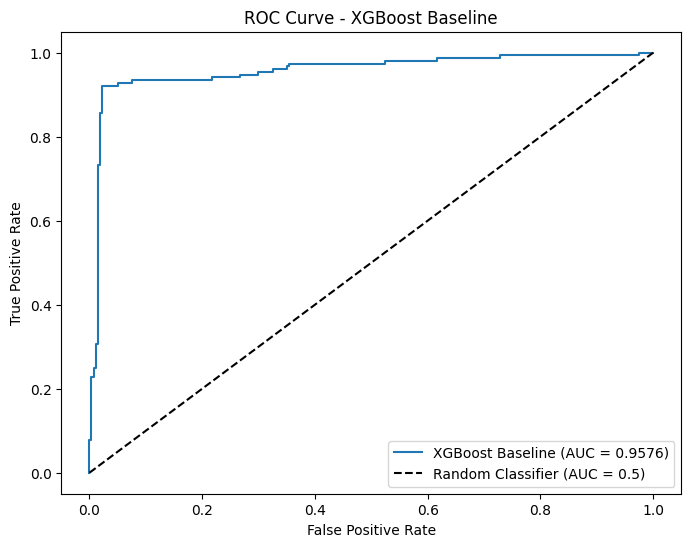

In [ ]:
#XGB Baseline

# Calculate ROC curve and AUC
xgb_baseline_fpr, xgb_baseline_tpr, _ = roc_curve(y_test, xgb_baseline_pred_proba)
xgb_baseline_auc = roc_auc_score(y_test, xgb_baseline_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(xgb_baseline_fpr, xgb_baseline_tpr, label=f'XGBoost Baseline (AUC = {xgb_baseline_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost Baseline')
plt.legend()
plt.show()

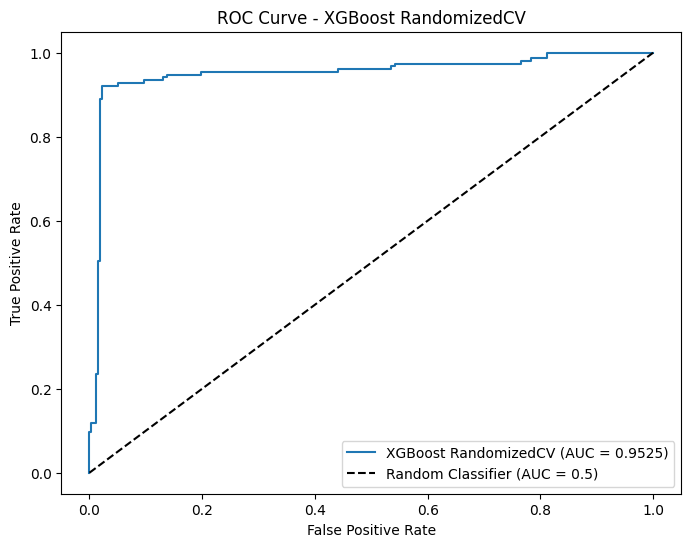

In [ ]:
# XGB Randomized

# Calculate ROC curve and AUC
xgb_random_fpr, xgb_random_tpr, _ = roc_curve(y_test, xgb_rand_best_pred_proba)
xgb_random_auc = roc_auc_score(y_test, xgb_rand_best_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(xgb_random_fpr, xgb_random_tpr, label=f'XGBoost RandomizedCV (AUC = {xgb_random_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost RandomizedCV')
plt.legend()
plt.show()

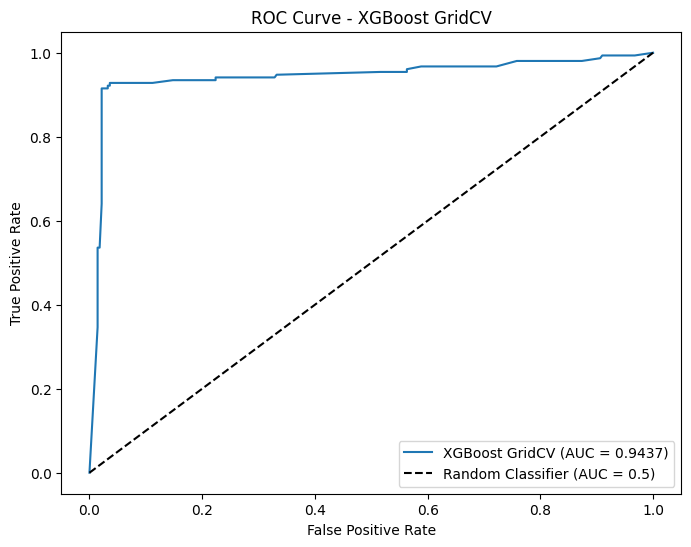

In [ ]:
# XGB Grid

# Calculate ROC curve and AUC
xgb_grid_fpr, xgb_grid_tpr, _ = roc_curve(y_test, xgb_grid_best_pred_proba)
xgb_grid_auc = roc_auc_score(y_test, xgb_grid_best_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(xgb_grid_fpr, xgb_grid_tpr, label=f'XGBoost GridCV (AUC = {xgb_grid_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost GridCV')
plt.legend()
plt.show()

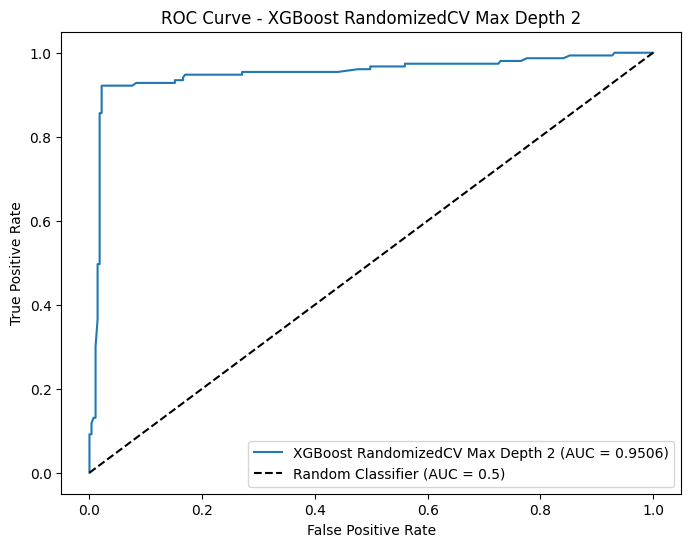

In [ ]:
# XGB Randomized (max_depth=2)

# Calculate ROC curve and AUC
xgb_rand_maxdepth2_fpr, xgb_rand_maxdepth2_tpr, _ = roc_curve(y_test, xgb_rand_maxdepth2_pred_proba)
xgb_rand_maxdepth2_auc = roc_auc_score(y_test, xgb_rand_maxdepth2_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(xgb_rand_maxdepth2_fpr, xgb_rand_maxdepth2_tpr, label=f'XGBoost RandomizedCV Max Depth 2 (AUC = {xgb_rand_maxdepth2_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost RandomizedCV Max Depth 2')
plt.legend()
plt.show()

###CatBoost Models

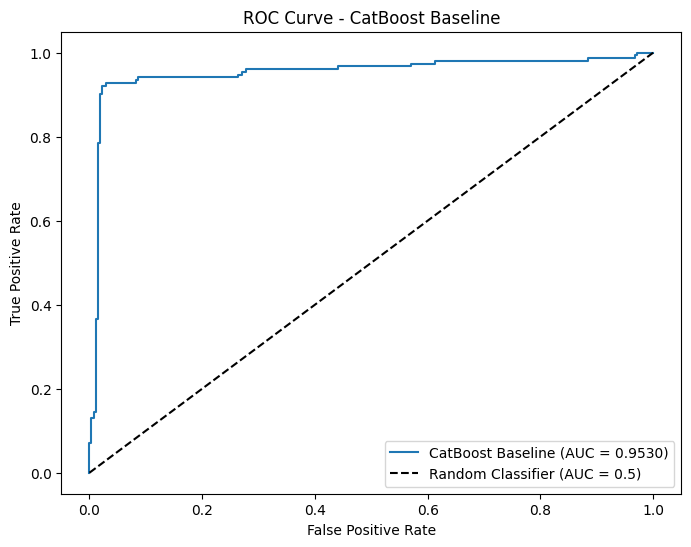

In [ ]:
# CatBoost Baseline

# Calculate ROC curve and AUC
cat_baseline_fpr, cat_baseline_tpr, _ = roc_curve(y_test, cat_baseline_pred_proba)
cat_baseline_auc = roc_auc_score(y_test, cat_baseline_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(cat_baseline_fpr, cat_baseline_tpr, label=f'CatBoost Baseline (AUC = {cat_baseline_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - CatBoost Baseline')
plt.legend()
plt.show()

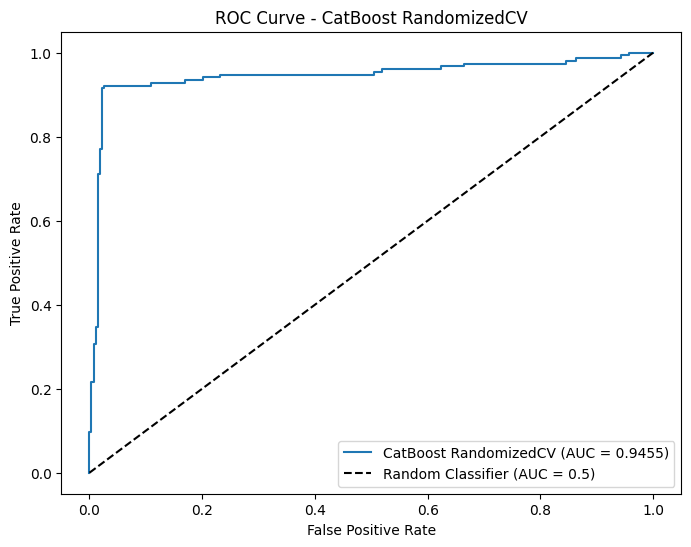

In [ ]:
# CatBoost Randomized

# Calculate ROC curve and AUC
cat_rand_fpr, cat_rand_tpr, _ = roc_curve(y_test, cat_rand_best_pred_proba)
cat_rand_auc = roc_auc_score(y_test, cat_rand_best_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(cat_rand_fpr, cat_rand_tpr, label=f'CatBoost RandomizedCV (AUC = {cat_rand_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - CatBoost RandomizedCV')
plt.legend()
plt.show()

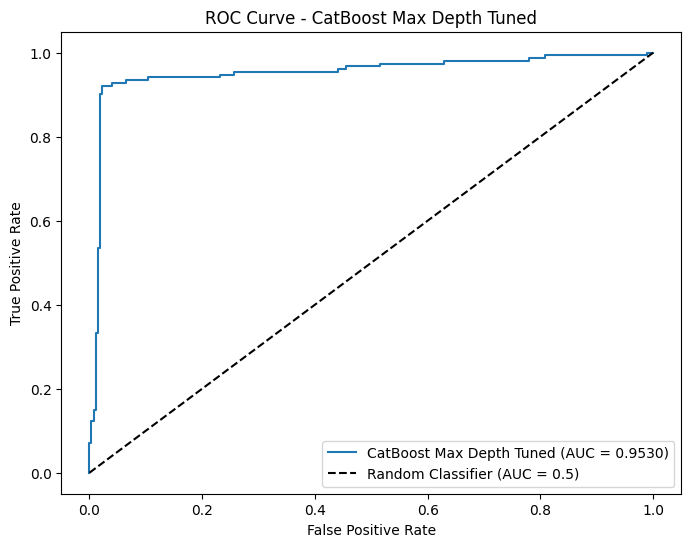

In [ ]:
# CatBoost Randomized (limited max_depth)

# Calculate ROC curve and AUC
cat_maxdepth_fpr, cat_maxdepth_tpr, _ = roc_curve(y_test, cat_maxdepth_pred_proba)
cat_maxdepth_auc = roc_auc_score(y_test, cat_maxdepth_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(cat_maxdepth_fpr, cat_maxdepth_tpr, label=f'CatBoost Max Depth Tuned (AUC = {cat_maxdepth_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - CatBoost Max Depth Tuned')
plt.legend()
plt.show()

###Neural Network

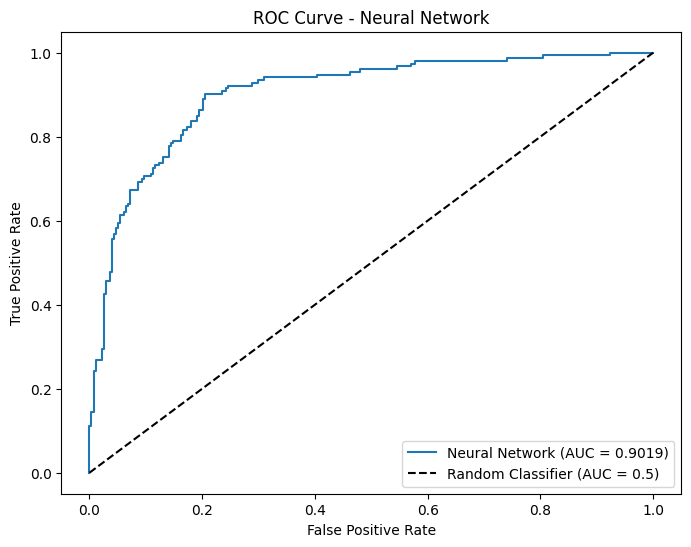

In [ ]:
# Calculate ROC curve and AUC
nn_fpr, nn_tpr, _ = roc_curve(y_test_tensor.numpy(), nn_pred_proba)
nn_auc = roc_auc_score(y_test_tensor.numpy(), nn_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(nn_fpr, nn_tpr, label=f'Neural Network (AUC = {nn_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Neural Network')
plt.legend()
plt.show()

#Comparison Table

In [ ]:
# Build data
### one row per model + type + class
rows = [
    #  model        type            class  prec   rec    f1     auc      overfit
    ("XGBoost",  "Baseline",        0,     0.95,  0.98,  0.97,  0.9576,  'Yes'),
    ("XGBoost",  "Baseline",        1,     0.96,  0.92,  0.94,  0.9576,  'Yes'),
    ("XGBoost",  "Randomized",      0,     0.96,  0.98,  0.97,  0.9525,  'No'),
    ("XGBoost",  "Randomized",      1,     0.96,  0.92,  0.94,  0.9525,  'No'),
    ("XGBoost",  "Grid",            0,     0.96,  0.97,  0.96,  0.9437,  'No'),
    ("XGBoost",  "Grid",            1,     0.94,  0.92,  0.93,  0.9437,  'No'),
    ("XGBoost",  "Max Depth=2",     0,     0.96,  0.97,  0.96,  0.9506,  'No'),
    ("XGBoost",  "Max Depth=2",     1,     0.95,  0.92,  0.93,  0.9506,  'No'),

    ("CatBoost", "Baseline",        0,     0.95,  0.98,  0.97,  0.9530,  'Yes'),
    ("CatBoost", "Baseline",        1,     0.96,  0.92,  0.94,  0.9530,  'Yes'),
    ("CatBoost", "Randomized",      0,     0.95,  0.98,  0.97,  0.9455,  'Yes'),
    ("CatBoost", "Randomized",      1,     0.96,  0.92,  0.94,  0.9455,  'Yes'),
    ("CatBoost", "Max Depth=2",     0,     0.95,  0.98,  0.96,  0.9530,  'No'),
    ("CatBoost", "Max Depth=2",     1,     0.96,  0.91,  0.93,  0.9530,  'No'),

    ("NeuralNet","Dropout",         0,     0.85,  0.89,  0.87,  0.9019,  'Yes'),
    ("NeuralNet","Dropout",         1,     0.78,  0.71,  0.75,  0.9019,  'Yes'),

]

cols = ["Model", "Type", "Class", "Precision", "Recall", "F1", "AUC", "Overfitting"]
df = pd.DataFrame(rows, columns=cols)

df["AUC"] = df["AUC"].apply(lambda x: f"{x:.4f}")

# 2. Set some columns as a hierarchical row index
df = df.set_index(["Model", "Type", "AUC", "Overfitting", "Class"])

In [ ]:
row_indices = []
prev_model = None
for i, (idx, _) in enumerate(df.iterrows()):
    current_model = idx[0]  # Model is the first index level
    if current_model != prev_model:
        row_indices.append(i)
        prev_model = current_model

# Build border styles for those rows
border_styles = []
for row_idx in row_indices:
    border_styles.append({
        "selector": f"tbody tr:nth-child({row_idx + 1}) td",
        "props": [("border-top", "2px solid black")]
    })
    border_styles.append({
        "selector": f"tbody tr:nth-child({row_idx + 1}) th",  # this covers the index columns
        "props": [("border-top", "2px solid black")]
    })


styled = (
    df.style
    .format({
        "Precision": "{:.2f}",
        "Recall":    "{:.2f}",
        "F1":        "{:.2f}"
    })
    .set_table_styles([
        {"selector": "thead th",
         "props": [("background-color", "#f8f9fa"), ("font-weight", "600"),
                   ("text-align", "center"), ("padding", "8px 12px"),
                   ("border-bottom", "2px solid #dee2e6")]},
        {"selector": "td, th",
         "props": [("padding", "6px 12px")]},

        *border_styles
    ])
    .set_caption("Model Performance: Baseline vs. Tuned — Per-Class Breakdown")
)

styled

#SHAP Feature Importance

In [ ]:
explainer = shap.TreeExplainer(cat_maxdepth_best_model)
shap_values = explainer.shap_values(X_test)

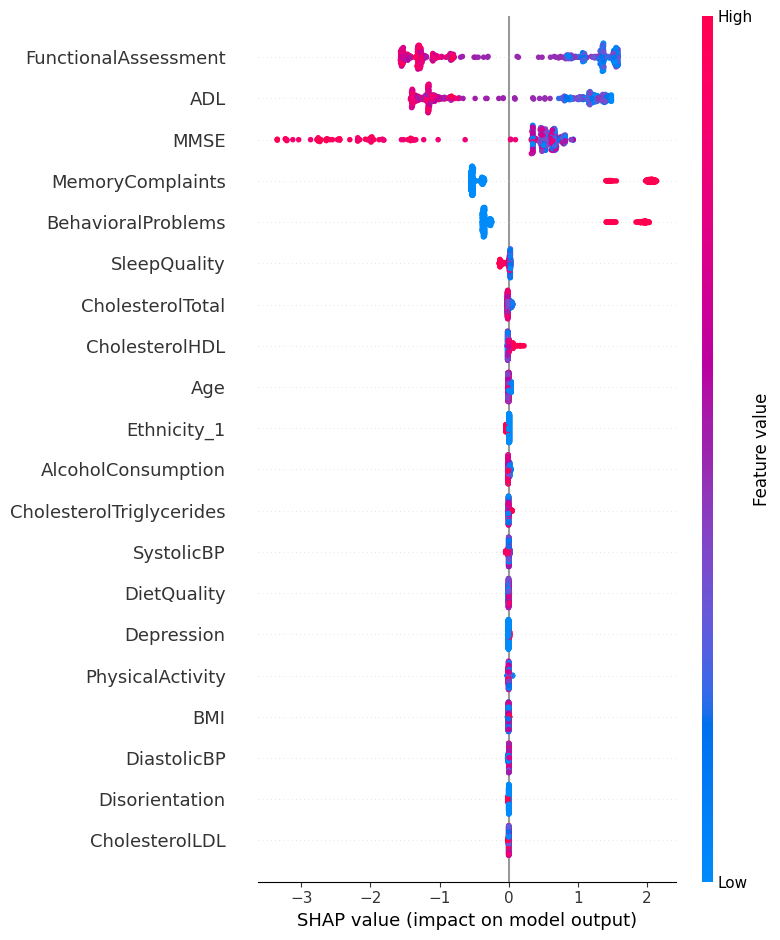

In [ ]:
shap.summary_plot(shap_values, X_test)